<center><h1>Do_Mimi_HW4</h1></center>
<br>
<br>

Name: Mimi Do
<br>
Github Username: mkd222
<br>
USC ID: 8125-6556-10

## 1. Time Series Classification Part 1: Feature Creation/Extraction (HW3 Rerun)

### (a) Obtain Data

Import packages

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import statsmodels.api as sm
from pathlib import Path
from sklearn.linear_model import LogisticRegression
from sklearn.feature_selection import RFE
from sklearn.model_selection import StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.metrics import confusion_matrix, roc_curve, auc, RocCurveDisplay
from sklearn.base import clone
from sklearn.naive_bayes import GaussianNB, MultinomialNB

Get the AReM Data Set

In [2]:
data_path = Path("../data")

print(data_path.exists())

True


### (b) Splitting Data

In [3]:
train_data = []
test_data = []

for folder in data_path.iterdir():
    if folder.is_dir():

        if folder.name in ["bending1", "bending2"]:
            test_csv = ["dataset1.csv", "dataset2.csv"]
        else:
            test_csv = ["dataset1.csv", "dataset2.csv", "dataset3.csv"]

        for csv in folder.glob("dataset*.csv"):
            if csv.name in test_csv:
                test_data.append(csv)
            else:
                train_data.append(csv)

print("Train Data Files:", len(train_data))
print("Test Data Files:", len(test_data))

Train Data Files: 69
Test Data Files: 19


### (c) Feature Extraction

In [4]:
all_features = []

all_files = sorted(train_data) + sorted(test_data)

for csv in all_files:
    if csv.parent.name == "bending2" and csv.name == "dataset4.csv":
        df = pd.read_csv(csv, comment = "#", header = None, sep = r"\s+")        # seperate by whitespace

    elif csv.parent.name == "cycling" and csv.name in ["dataset9.csv", "dataset14.csv"]:
        df = pd.read_csv(csv, comment = "#", header = None, usecols = range(7))         # only use first 7 columns, column 8 only has a comma 

    else:
        df = pd.read_csv(csv, comment = "#", header = None)

    features = {}

    for i in range(1, 7):
        time_series = df[i]

        features[f"minimum{i}"] = time_series.min()
        features[f"maximum{i}"] = time_series.max()
        features[f"mean{i}"] = time_series.mean()
        features[f"median{i}"] = time_series.median()
        features[f"standard deviation{i}"] = time_series.std()
        features[f"first quartile{i}"] = time_series.quantile(0.25)
        features[f"third quartile{i}"] = time_series.quantile(0.75)

    all_features.append(features)

df_features = pd.DataFrame(all_features)

df_features.index = range(1, len(df_features) + 1)
df_features.index.name = "Instance"

df_features.head()

,minimum1,maximum1,mean1,median1,standard deviation1,first quartile1,third quartile1,minimum2,maximum2,mean2,...,standard deviation5,first quartile5,third quartile5,minimum6,maximum6,mean6,median6,standard deviation6,first quartile6,third quartile6
Instance,,,,,,,,,,,,,,,,,,,,,
1,35.00,47.40,43.954500,44.33,1.558835,43.00,45.00,0.0,1.70,0.426250,...,1.999604,35.3625,36.50,0.0,1.79,0.493292,0.43,0.513506,0.00,0.94
2,33.00,47.75,42.179812,43.50,3.670666,39.15,45.00,0.0,3.00,0.696042,...,3.849448,30.4575,36.33,0.0,2.18,0.613521,0.50,0.524317,0.00,1.00
3,33.00,45.75,41.678063,41.75,2.243490,41.33,42.75,0.0,2.83,0.535979,...,2.411026,28.4575,31.25,0.0,1.79,0.383292,0.43,0.389164,0.00,0.50
4,37.00,48.00,43.454958,43.25,1.386098,42.50,45.00,0.0,1.58,0.378083,...,2.488862,22.2500,24.00,0.0,5.26,0.679646,0.50,0.622534,0.43,0.87
5,36.25,48.00,43.969125,44.50,1.618364,43.31,44.67,0.0,1.50,0.413125,...,3.318301,20.5000,23.75,0.0,2.96,0.555312,0.49,0.487826,0.00,0.83


## 2. Time Series Classification Part 2: Binary and Multiclass Classification

### (a) Binary Classification Using Logistic Regression

#### i. Plots

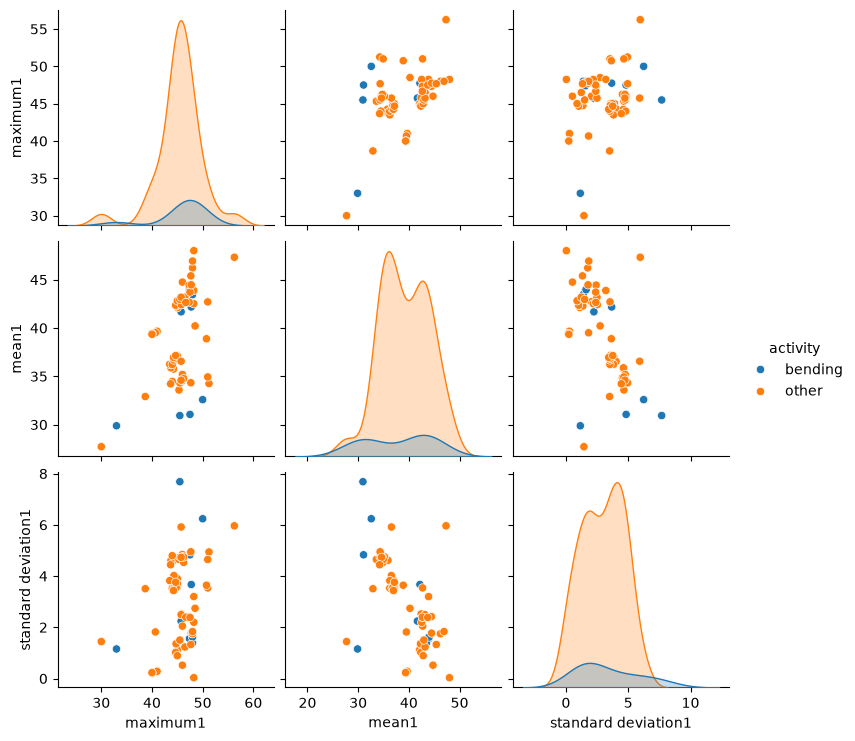

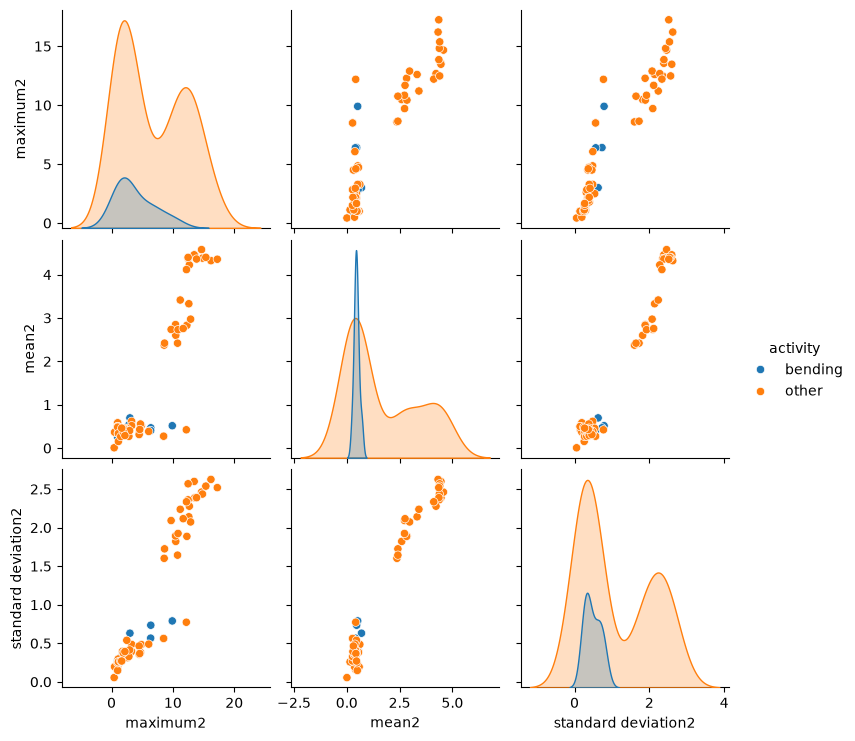

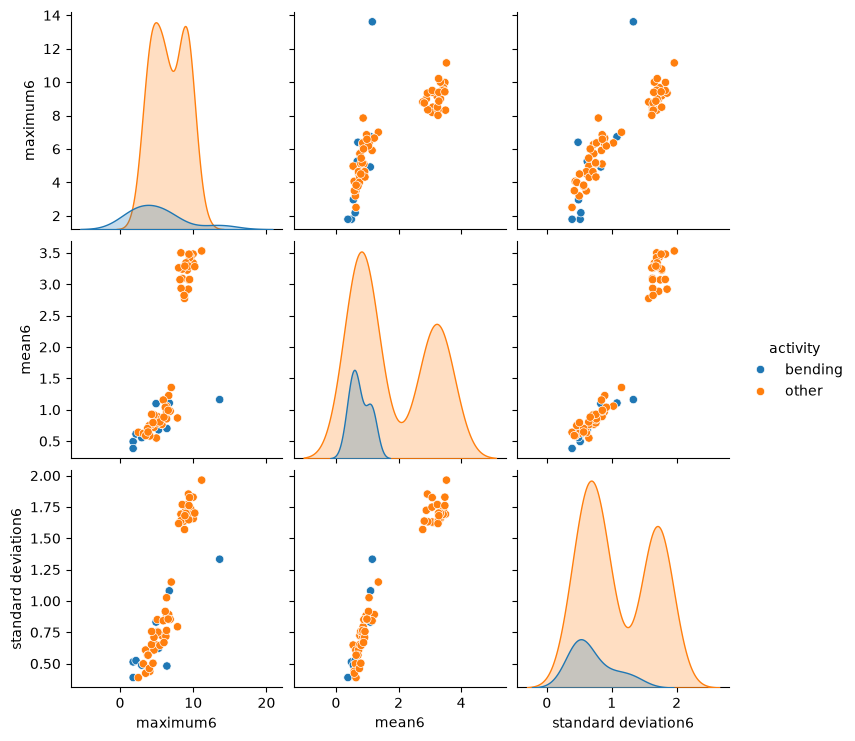

In [5]:
train_features = df_features.iloc[:len(train_data)].copy()

train_files = sorted(train_data)

train_features["activity"] = ["bending" if csv.parent.name in ["bending1", "bending2" ] else "other" for csv in train_files]

for i in [1, 2, 6]:
    columns = [
        f"maximum{i}", 
        f"mean{i}", 
        f"standard deviation{i}"]
    sns.pairplot(train_features, vars = columns, hue = "activity")
    plt.show()

#### ii. Splitted Plots

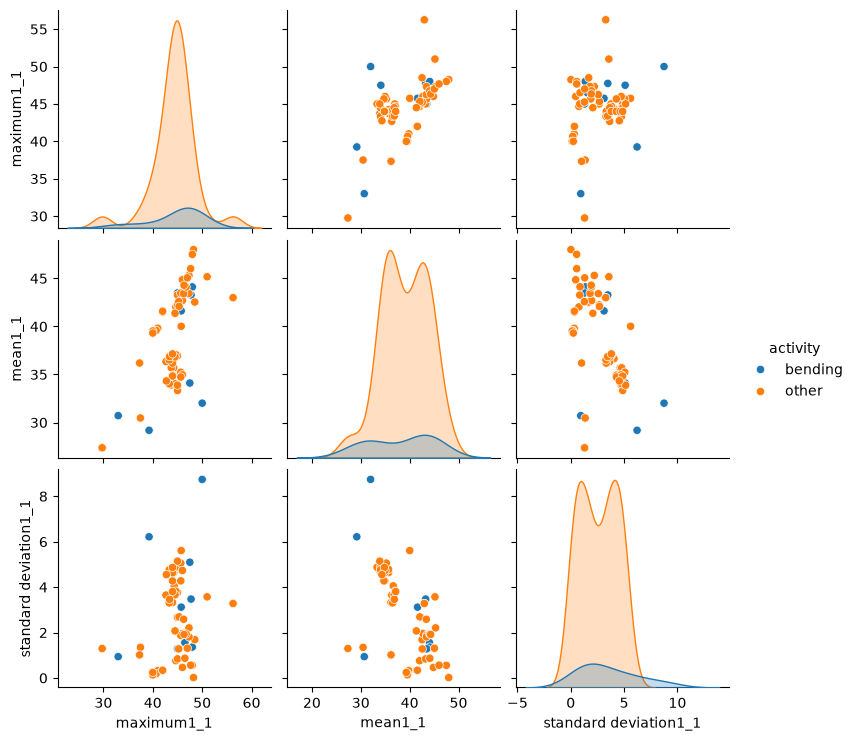

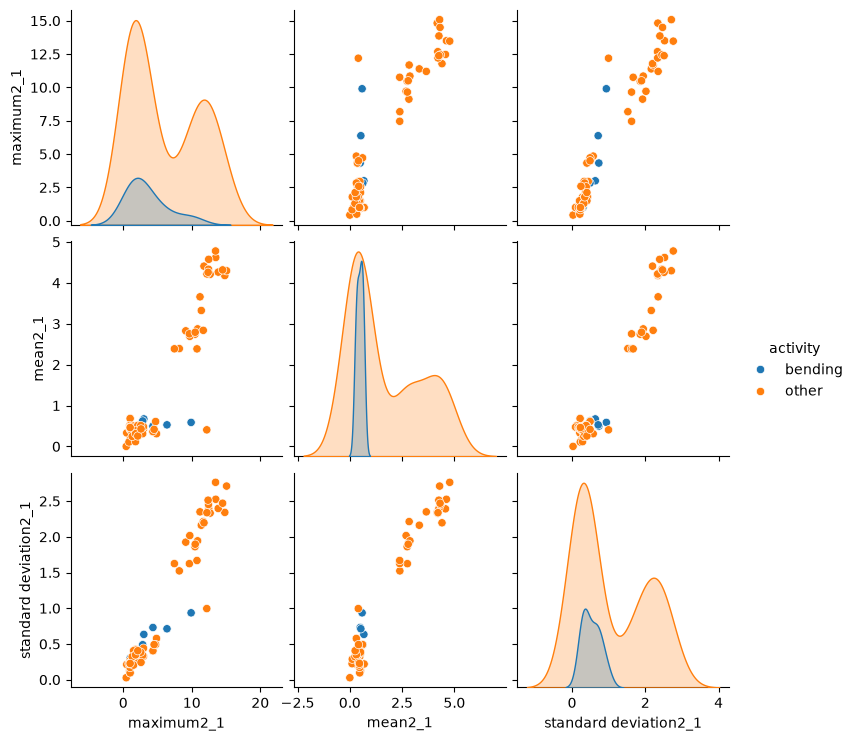

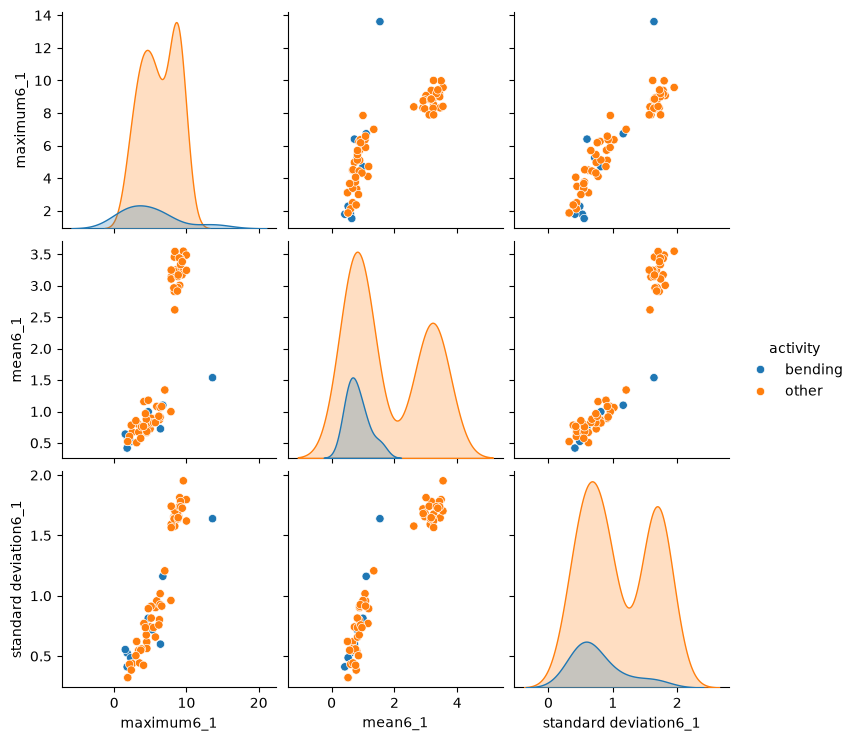

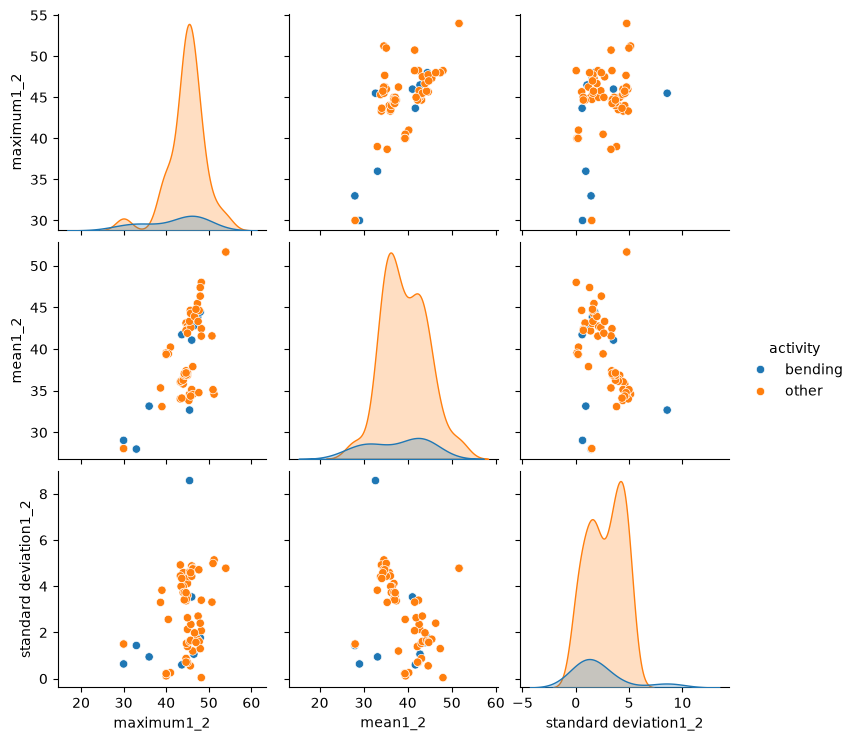

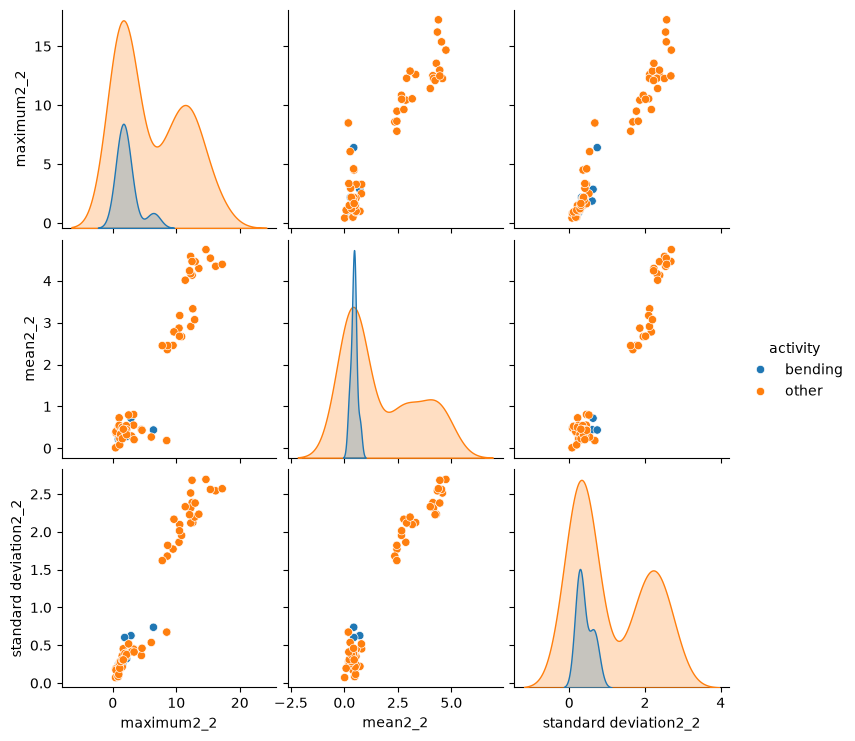

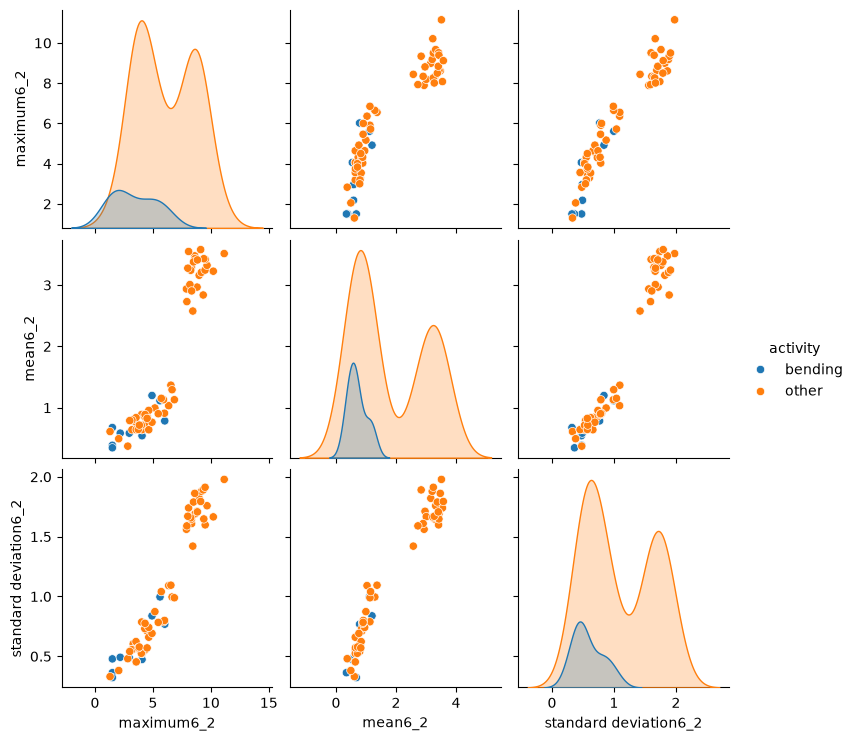

In [6]:
split_features_half = []

for csv in train_files:
    if csv.parent.name == "bending2" and csv.name == "dataset4.csv":
        df = pd.read_csv(csv, comment = "#", header = None, sep = r"\s+")        

    elif csv.parent.name == "cycling" and csv.name in ["dataset9.csv", "dataset14.csv"]:
        df = pd.read_csv(csv, comment = "#", header = None, usecols = range(7))         

    else:
        df = pd.read_csv(csv, comment = "#", header = None)

    half = len(df) // 2
    half1 = df.iloc[:half]
    half2 = df.iloc[half:]

    features = {}

    for i in range(1, 7):
        time_series1 = half1[i]
        time_series2 = half2[i]

        features[f"maximum{i}_1"] = time_series1.max()
        features[f"mean{i}_1"] = time_series1.mean()
        features[f"standard deviation{i}_1"] = time_series1.std()
        features[f"maximum{i}_2"] = time_series2.max()
        features[f"mean{i}_2"] = time_series2.mean()
        features[f"standard deviation{i}_2"] = time_series2.std()

    split_features_half.append(features)

df_split_half = pd.DataFrame(split_features_half)

df_split_half["activity"] = ["bending" if csv.parent.name in ["bending1", "bending2" ] else "other" for csv in train_files]

for x in [1, 2]:
    for i in [1, 2, 6]:
        columns = [
            f"maximum{i}_{x}",
            f"mean{i}_{x}",
            f"standard deviation{i}_{x}"]
        sns.pairplot(df_split_half, vars = columns, hue = "activity")
        plt.show()

From visual observation, there seems to be no considerable differences between the original and split scatter plots. It appears that there are slight changes in distribution and spread of the data points but the overall patterns are still similar.

#### iii. Time Series Segments

##### Splitting time series into $l$ & feature extraction

In [7]:
split_features_l = {}

for l in range(1, 21):
    split_features = []

    for csv in train_files:
        if csv.parent.name == "bending2" and csv.name == "dataset4.csv":
            df = pd.read_csv(csv, comment = "#", header = None, sep = r"\s+")        
        
        elif csv.parent.name == "cycling" and csv.name in ["dataset9.csv", "dataset14.csv"]:
            df = pd.read_csv(csv, comment = "#", header = None, usecols = range(7))         
        
        else:
            df = pd.read_csv(csv, comment = "#", header = None)

        features = {}

        for i in range(1, 7):
            lengths = np.array_split(df[i].to_numpy(), l)        # Divides time series into l equal lengths

            for length in range(1, l + 1):
                time_series = pd.Series(lengths[length - 1])

                features[f"minimum{i}_{length}"] = time_series.min()
                features[f"maximum{i}_{length}"] = time_series.max()
                features[f"mean{i}_{length}"] = time_series.mean()
                features[f"median{i}_{length}"] = time_series.median()
                features[f"standard deviation{i}_{length}"] = time_series.std()
                features[f"first quartile{i}_{length}"] = time_series.quantile(0.25)
                features[f"third quartile{i}_{length}"] = time_series.quantile(0.75)

        split_features.append(features)

    df_split_l = pd.DataFrame(split_features)

    df_split_l["activity"] = ["bending" if csv.parent.name in ["bending1", "bending2" ] else "other" for csv in train_files]

    split_features_l[l] = df_split_l

# Accuracy Check
for l in [1, 2, 20]:
    print(f"l = {l}: {split_features_l[l].shape}")

l = 1: (69, 43)
l = 2: (69, 85)
l = 20: (69, 841)


##### Finding best $(l, p)$
Initial pipeline accuracy check for logistic regression, RFE, and cross-validation when $l = 1$. I want to make sure that my pipeline works correctly before testing more combinations.

In [8]:
X = split_features_l[1].drop(columns = ["activity"])
y = split_features_l[1]["activity"]

cross_val = StratifiedKFold(n_splits = 5, shuffle = True, random_state = 1)

log_reg_model = LogisticRegression(C = np.inf)      # Modify max_iter if there is instability

rfe = RFE(estimator = log_reg_model)
pipeline = Pipeline([
    ("standardize", StandardScaler()),
    ("rfe", rfe),
    ("logistic regression", log_reg_model)])

scores = cross_val_score(pipeline, X, y, cv = cross_val, scoring = "accuracy")

print(scores.mean())
print(1 - scores.mean())

0.9571428571428571
0.04285714285714293


Testing some values of $p$ for every $l$. Testing every $(l, p)$ combination would be too costly.
-   Best combination is $(1, 5)$ where accuracy is 100% and error is 0%

In [9]:
results = []

for l in range(1, 21):
    X = split_features_l[l].drop(columns = ["activity"])
    y = split_features_l[l]["activity"]

    for p in [5, 10, 20, 30, 40]:
        pipeline.set_params(rfe__n_features_to_select = p, rfe__step = 0.2)
        scores = cross_val_score(pipeline, X, y, cv = cross_val, scoring = "accuracy")
        accuracy = scores.mean()
        error = 1- accuracy

        results.append({
            "l": l,
            "p": p,
            "accuracy": accuracy,
            "error": error})

df_results = pd.DataFrame(results)
df_results = df_results.sort_values(by = "error")
df_results.head(5)

,l,p,accuracy,error
0,1,5,1.000000,0.000000
26,6,10,0.970330,0.029670
2,1,20,0.957143,0.042857
30,7,5,0.956044,0.043956
25,6,5,0.954945,0.045055


##### Fitting logistic regression model using best $(l, p)$ & selecting best features

In [10]:
best_l = 1
best_p = 5

X_best = split_features_l[best_l].drop(columns = ["activity"])
y_best = split_features_l[best_l]["activity"]

pipeline.set_params(rfe__n_features_to_select = best_p, rfe__step = 0.2)
pipeline.fit(X_best, y_best)

features_selected = X_best.columns[pipeline.named_steps["rfe"].support_]        # returns Boolean for features selected 

print(features_selected.tolist())

['third quartile1_1', 'maximum2_1', 'minimum5_1', 'maximum5_1', 'first quartile6_1']


Right way to perform cross-validation: Split training data into folds and perform feature selection using only the training portion of each fold, then evaluate the model on the validation data. This prevents data leakage and gives a better estimate of model performance.
<br>
Wrong way to perform cross-validation: Selecting features using the entire dataset before dividing into folds. This causes data leakage, leading to inaccurate results.

#### iv. Confusion Matrix

In [11]:
y_predict = pipeline.predict(X_best)

cm = confusion_matrix(y_best, y_predict)
print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[ 9  0]
 [ 0 60]]


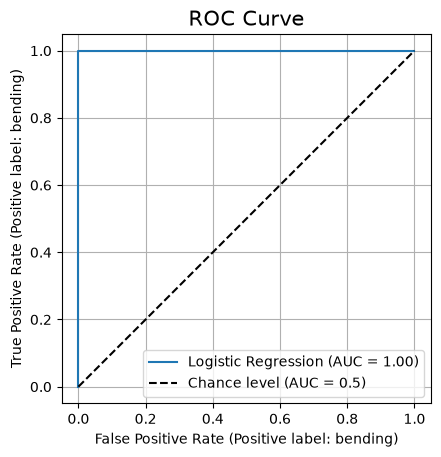

In [12]:
roc_visual = RocCurveDisplay.from_estimator(
    pipeline,
    X_best,
    y_best,
    pos_label = "bending",
    name = "Logistic Regression",
    plot_chance_level = True)

plt.title("ROC Curve", fontsize = 15)
plt.ylim(-0.05, 1.05)
plt.xlim(-0.05, 1.05)
plt.grid()
plt.show()

In [13]:
selc_features = pipeline.named_steps["rfe"].support_

X_norm = pipeline.named_steps["standardize"].transform(X_best)
x = X_norm[:, selc_features]
X_const = sm.add_constant(x)

y = (y_best == "bending").astype(int)

log_model = sm.Logit(y, X_const)
summary = log_model.fit(method = "bfgs").summary()
print(summary)

Optimization terminated successfully.
         Current function value: 0.000005
         Iterations: 21
         Function evaluations: 22
         Gradient evaluations: 22
                           Logit Regression Results                           
Dep. Variable:               activity   No. Observations:                   69
Model:                          Logit   Df Residuals:                       63
Method:                           MLE   Df Model:                            5
Date:                Tue, 20 Oct 2026   Pseudo R-squ.:                   1.000
Time:                        03:31:55   Log-Likelihood:            -0.00032712
converged:                       True   LL-Null:                       -26.718
Covariance Type:            nonrobust   LLR p-value:                 2.739e-10
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const        -45.1670   6.18e+05   -7.

#### v. Test Classifier

In [14]:
X_test = df_features.iloc[len(train_data):].copy()

X_test.columns = [f"{columns}_1" for columns in X_test.columns]
X_test = X_test[X_best.columns]

y_test = ["bending" if csv.parent.name in ["bending1", "bending2" ] else "other" for csv in sorted(test_data)]

test_accuracy = pipeline.score(X_test, y_test)

print(test_accuracy)

1.0


Test accuracy is the same 

#### vi. Separation

The classes appear to be well-seperated as shown in the model summary, resulting in instability.

#### vii. Imbalance

Confusion Matrix:
[[ 9  0]
 [ 1 59]]


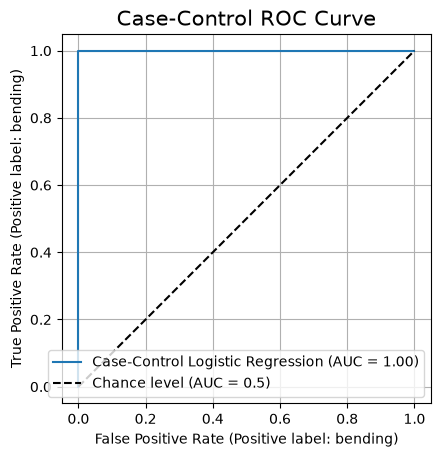

In [15]:
df_case_control = split_features_l[best_l]

bending = df_case_control[df_case_control["activity"] == "bending"]
other = df_case_control[df_case_control["activity"] == "other"].sample(n = 9, random_state = 1)

df_bal = pd.concat([bending, other])

X_bal = df_bal.drop(columns = ["activity"])
y_bal = df_bal["activity"]

bal_model = clone(pipeline)
bal_model.fit(X_bal, y_bal)

adjust = np.log((60 / 9) / (9 / 9))     # adjust parameters
bal_model.named_steps["logistic regression"].intercept_[0] += adjust

y_predict = bal_model.predict(X_best)

cm = confusion_matrix(y_best, y_predict)
print("Confusion Matrix:")
print(cm)

roc_visual = RocCurveDisplay.from_estimator(
    bal_model,
    X_best,
    y_best,
    pos_label = "bending",
    name = "Case-Control Logistic Regression",
    plot_chance_level = True)

plt.title("Case-Control ROC Curve", fontsize = 15)
plt.ylim(-0.05, 1.05)
plt.xlim(-0.05, 1.05)
plt.grid()
plt.show()

### (b) Binary Classification Using L1-penalized logistic regression

#### i. Time Series Segments

In [16]:
pen_model = LogisticRegression(solver = "liblinear", l1_ratio = 1)

pen_pipeline = Pipeline([
    ("standardize", StandardScaler()),
    ("logistic regression", pen_model)])

pen_results = []
pen_models = {}

for l in range(1, 21):
    X = split_features_l[l].drop(columns = ["activity"])
    y = split_features_l[l]["activity"]

    search = GridSearchCV(                                          # auto test C from cross_val
        pen_pipeline,
        {"logistic regression__C": [1, 10]},
        cv = cross_val,
        scoring = "accuracy")

    search.fit(X, y)

    pen_results.append({
        "l": l,
        "C": search.best_params_["logistic regression__C"],
        "accuracy": search.best_score_,
        "error": 1 - search.best_score_})

    pen_models[l] = search.best_estimator_

df_pen_results = pd.DataFrame(pen_results)
df_pen_results = df_pen_results.sort_values(by = ["error", "l"])
df_pen_results.head(5)

,l,C,accuracy,error
0,1,1,0.970330,0.029670
12,13,1,0.957143,0.042857
17,18,1,0.957143,0.042857
2,3,1,0.956044,0.043956
4,5,1,0.942857,0.057143


#### ii. Comparison

RFE performed better with 100% accuracy compared to $l1$-penalized at 97.03%. $l1$ regularization is easier to implement because feature selection is not manual

### (c) Multi-class Classification (The Realistic Case)

#### i. Time Series Segments

-   I decided to only use three features instead of all seven because it was too much computationally and was causing convergence issues. I kept the same three features for both Naive Bayes models to keep it consistent.
-   I combined bending1 and bending2 into one class "bending" because they represent the same activity.

In [17]:
test_files = sorted(test_data)

y_train_multiclass = ["bending" if csv.parent.name in ["bending1", "bending2" ] else csv.parent.name for csv in train_files]
y_test_multiclass = ["bending" if csv.parent.name in ["bending1", "bending2" ] else csv.parent.name for csv in test_files]

multiclass_model = LogisticRegression(solver = "saga", l1_ratio = 1, max_iter = 5000)

multiclass_pipeline = Pipeline([
    ("standardize", StandardScaler()),
    ("logistic regression", multiclass_model)])

multiclass_results = []
multiclass_models = {}

for l in range(1, 21):
    X = split_features_l[l][[column for column in split_features_l[l].columns if column.startswith(("maximum", "mean", "standard deviation"))]]
    
    search = GridSearchCV(                                          # auto test C from cross_val
        multiclass_pipeline,
        {"logistic regression__C": [0.1, 1]},
        cv = cross_val,
        scoring = "accuracy")

    search.fit(X, y_train_multiclass)

    multiclass_results.append({
        "l": l,
        "C": search.best_params_["logistic regression__C"],
        "accuracy": search.best_score_,
        "error": 1 - search.best_score_})

    multiclass_models[l] = search.best_estimator_

df_multiclass_results = pd.DataFrame(multiclass_results)
df_multiclass_results = df_multiclass_results.sort_values(by = ["error", "l"])
df_multiclass_results.head(5)

,l,C,accuracy,error
0,1,1,0.913187,0.086813
1,2,1,0.871429,0.128571
19,20,1,0.856044,0.143956
2,3,1,0.828571,0.171429
4,5,1,0.828571,0.171429


Multiclass best $l$ = 1

test accuracy =  0.8947368421052632
test error =  0.10526315789473684
Confusion Matrix:
[[4 0 0 0 0 0]
 [0 3 0 0 0 0]
 [0 0 3 0 0 0]
 [0 0 0 2 1 0]
 [0 0 0 1 2 0]
 [0 0 0 0 0 3]]


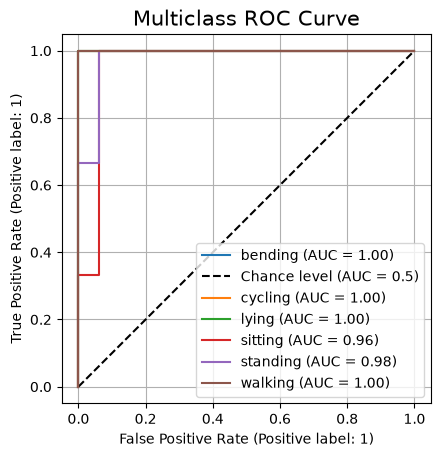

In [18]:
best_l_multiclass = 1
best_multiclass_model = multiclass_models[best_l_multiclass]

X_test_multiclass = df_features.iloc[len(train_data):].copy()
X_test_multiclass.columns = [f"{columns}_1" for columns in X_test_multiclass.columns]

X_train_multiclass = split_features_l[best_l_multiclass][[column for column in split_features_l[best_l_multiclass].columns if column.startswith(("maximum", "mean", "standard deviation"))]]
X_test_multiclass = X_test_multiclass[X_train_multiclass.columns]

test_accuracy_multiclass = best_multiclass_model.score(X_test_multiclass, y_test_multiclass)
print("test accuracy = ", test_accuracy_multiclass)
print("test error = ", 1 - test_accuracy_multiclass)

y_predict_multiclass = best_multiclass_model.predict(X_test_multiclass)
cm = confusion_matrix(y_test_multiclass, y_predict_multiclass)
print("Confusion Matrix:")
print(cm)

classes = best_multiclass_model.classes_
proba = best_multiclass_model.predict_proba(X_test_multiclass)

fig, ax = plt.subplots()

for i, activity in enumerate(classes):
    y_label = np.array(y_test_multiclass) == activity

    RocCurveDisplay.from_predictions(
        y_label,
        proba[:, i],
        name = activity,
        ax = ax,
        plot_chance_level = (i == 0))
plt.title("Multiclass ROC Curve", fontsize = 15)
plt.ylim(-0.05, 1.05)
plt.xlim(-0.05, 1.05)
plt.grid()
plt.show()

#### ii. Naive Bayes

In [19]:
naive_bayes_models = {
    "gaussian": Pipeline([
        ("model", GaussianNB())]),
    
    "multinomial": Pipeline([
        ("scaler", MinMaxScaler(clip = True)),
        ("model", MultinomialNB())])}

naive_bayes_results = []

for name, model in naive_bayes_models.items():
    for l in range(1, 21):
        X = split_features_l[l][[column for column in split_features_l[l].columns if column.startswith(("maximum", "mean", "standard deviation"))]]

        scores = cross_val_score(
            model, X, y_train_multiclass,
            cv = cross_val, scoring = "accuracy")
        
        naive_bayes_results.append({
            "model": name,
            "l": l,
            "accuracy": scores.mean(),
            "error": 1 - scores.mean()})

df_naive_bayes_results = pd.DataFrame(naive_bayes_results)
df_naive_bayes_results = df_naive_bayes_results.sort_values(by =["model", "error", "l"])
df_naive_bayes_results.groupby("model").head(1)

,model,l,accuracy,error
5,gaussian,6,0.87033,0.12967
24,multinomial,5,0.77033,0.22967


Gaussian best $l$ = 6
<br>
Multinomial best $l$ = 5

Confusion Matrix:
[[4 0 0 0 0 0]
 [0 3 0 0 0 0]
 [0 0 3 0 0 0]
 [0 0 0 2 1 0]
 [0 0 0 1 2 0]
 [0 0 0 0 0 3]]


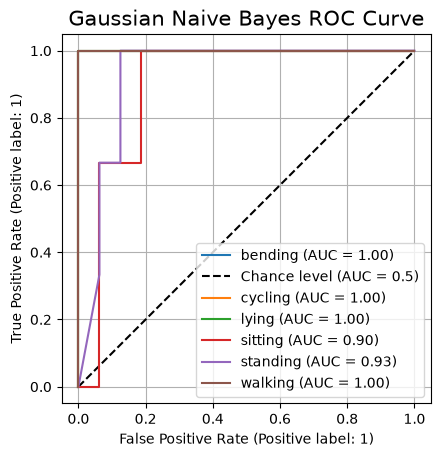

Confusion Matrix:
[[3 0 0 0 1 0]
 [0 3 0 0 0 0]
 [0 0 2 1 0 0]
 [0 0 0 2 1 0]
 [0 0 0 1 2 0]
 [0 0 0 0 0 3]]


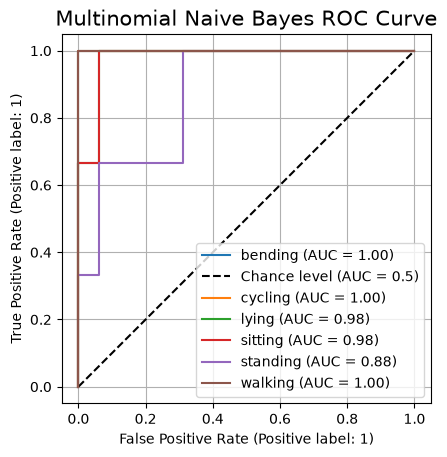

In [20]:
naive_bayes_test_results = []

for name, model in naive_bayes_models.items():
    best = df_naive_bayes_results[df_naive_bayes_results["model"] == name].sort_values("error").iloc[0]
    l = int(best["l"])

    X_train = split_features_l[l][[column for column in split_features_l[l].columns if column.startswith(("maximum", "mean", "standard deviation"))]]

    test_features = []

    for csv in test_files:
        if csv.parent.name == "bending2" and csv.name == "dataset4.csv":
            df = pd.read_csv(csv, comment = "#", header = None, sep = r"\s+")        
            
        elif csv.parent.name == "cycling" and csv.name in ["dataset9.csv", "dataset14.csv"]:
            df = pd.read_csv(csv, comment = "#", header = None, usecols = range(7))         
            
        else:
            df = pd.read_csv(csv, comment = "#", header = None)
    
        features = {}
    
        for i in range(1, 7):
            lengths = np.array_split(df[i].to_numpy(), l)        
    
            for length in range(1, l + 1):
                time_series = pd.Series(lengths[length - 1])
                
                features[f"maximum{i}_{length}"] = time_series.max()
                features[f"mean{i}_{length}"] = time_series.mean()
                features[f"standard deviation{i}_{length}"] = time_series.std()

        test_features.append(features)

    X_test = pd.DataFrame(test_features)
    X_test = X_test[X_train.columns]

    fit_model = clone(model)
    fit_model.fit(X_train, y_train_multiclass)

    test_accuracy = fit_model.score(X_test, y_test_multiclass)

    naive_bayes_test_results.append({
        "model": name,
        "l": l,
        "test accuracy": test_accuracy,
        "test error": 1 - test_accuracy})

    y_predict = fit_model.predict(X_test)

    cm = confusion_matrix(y_test_multiclass, y_predict)
    print("Confusion Matrix:")
    print(cm)

    classes = fit_model.classes_
    proba = fit_model.predict_proba(X_test)

    fig, ax = plt.subplots()
    
    for i, activity in enumerate(classes):
        y_label = np.array(y_test_multiclass) == activity

        RocCurveDisplay.from_predictions(
            y_label,
            proba[:, i],
            name = activity,
            ax = ax,
            plot_chance_level = (i == 0))

    plt.title(f"{name.capitalize()} Naive Bayes ROC Curve", fontsize = 15)
    plt.ylim(-0.05, 1.05)
    plt.xlim(-0.05, 1.05)
    plt.grid()
    plt.show()

#### ii. Comparison

Gaussian performed better than Multinomial, with accuracy at 87% compared to Multinomial at 77%. Additionally, Gaussian misclassified 2 instances while Multinomial misclassified 4.

#### iii. Better Method

$l1$ penalized multinomial regression is the better method because it achieved the highest cross-val accuracy at 91%. 

## 3. ISLR 4.8.3

The Gaussian discriminant function is:
$$\delta_k(x)=\log(\pi_k)-\frac12\log(\sigma_k^2)-\frac{(x-\mu_k)^2}{2\sigma_k^2}$$
Expand squared term:
$$\delta_k(x)=-\frac{x^2}{2\sigma_k^2}+\frac{\mu_k x}{\sigma_k^2}-\frac{\mu_k^2}{2\sigma_k^2}-\frac12\log(\sigma_k^2)+\log(\pi_k)$$
The quadratic term is:
$$-\frac{x^2}{2\sigma_k^2}$$
The discriminant function contains the quadratic term, therefore is not linear


## 4. ISLR 4.8.7

Normal density for companies that issued dividends:
$$f_{\text{Yes}}(4) = \frac{1}{\sqrt{72\pi}}e^{-\frac{(4-10)^2}{72}}$$
$$= \frac{1}{\sqrt{72\pi}}e^{-0.5}$$
Normal density for companies that didn't issue dividends:
$$f_{\text{No}}(4) = \frac{1}{\sqrt{72\pi}}e^{-\frac{(4-0)^2}{72}}$$
$$= \frac{1}{\sqrt{72\pi}}e^{-16/72}$$
Plug into Bayes theorem:
$$P(\text{Yes} \mid X = 4) = \frac{0.8e^{-0.5}}{0.8e^{-0.5} + 0.2e^{-16/72}}$$
$$\boxed{P(\text{Yes} \mid X = 4) \approx 0.75}$$

#### References
-   https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html
-   https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.StratifiedKFold.html
-   https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.Pipeline.html
-   https://scikit-learn.org/stable/modules/generated/sklearn.feature_selection.RFE.html